# Uygulama 1: Iris Çiçek Türlerini Sınıflandırma

**Makine Öğrenmesi**

| | |
|---|---|
| **Veri seti** | Iris: 150 çiçek, 4 ölçüm, 3 tür |
| **Veri kaynağı** | CSV dosyası (`iris.csv`) |
| **Görev** | Sınıflandırma: çiçeğin türünü tahmin etmek |
| **Öğrenme türü** | Gözetimli öğrenme, etiketli veri |
| **Algoritmalar** | K-En Yakın Komşu (KNN), Karar Ağacı |

### Bu uygulamada yapacaklarımız
1. Gerekli kütüphaneleri yüklemek ve her birinin ne işe yaradığını görmek
2. Bir CSV dosyasının içine bakmak ve onu tabloya dönüştürmek
3. Veriyi tanımak ve grafiklerle incelemek
4. Özellikleri (X) ve etiketi (y) ayırmak
5. Veriyi eğitim ve test olarak bölmek
6. KNN modelini eğitmek ve test etmek
7. Sonuçları doğruluk ve karmaşıklık matrisi ile yorumlamak
8. k değerinin etkisini incelemek
9. Karar ağacı ile kuralları görmek
10. Yeni bir çiçek için tahmin yapmak

Hücreleri yukarıdan aşağıya `Shift + Enter` ile sırayla çalıştırın. Bir hücre hata verirse önce kendisinden önceki hücrelerin çalıştırılmış olduğunu kontrol edin.

---
## 1. Kütüphaneleri yüklemek

Python'da her işlevi sıfırdan yazmayız. Başkalarının yazdığı ve herkesin kullanımına açtığı hazır kod paketlerini, yani **kütüphaneleri**, programımıza dahil ederiz. Bunu `import` komutuyla yaparız. `import pandas as pd` ifadesindeki `as pd`, kütüphaneye kısa bir takma ad verir; böylece her seferinde `pandas` yerine `pd` yazarız.

Google Colab'de bu kütüphanelerin hepsi kurulu gelir; ayrıca bir şey yüklemeye gerek yoktur.

Bu uygulamada kullanacağımız kütüphaneler ve neden kullandığımız:

| Kütüphane | Ne işe yarar? | Bu uygulamada neden kullanıyoruz? |
|---|---|---|
| **pandas** (`pd`) | Tablo şeklindeki verilerle çalışmayı sağlar. Excel tablosunun Python'daki karşılığı gibidir. | CSV dosyasını okumak, tabloyu incelemek, sütun seçmek |
| **NumPy** (`np`) | Sayı dizileri üzerinde hızlı matematiksel işlemler yapar. pandas da arka planda NumPy kullanır. | Sayı aralıkları oluşturmak, karşılaştırma yapmak |
| **Matplotlib** (`plt`) | Python'un temel grafik çizim kütüphanesidir. | Grafiklerin başlığını, eksen adlarını ve boyutunu ayarlamak |
| **Seaborn** (`sns`) | Matplotlib üzerine kurulu, istatistiksel grafikleri kolayca çizen kütüphane. | Türlere göre renklendirilmiş dağılım ve kutu grafikleri çizmek |
| **scikit-learn** (`sklearn`) | Makine öğrenmesi algoritmalarını, veri bölme ve değerlendirme araçlarını içerir. | Veriyi bölmek, modelleri eğitmek ve başarıyı ölçmek |

In [1]:
# Tablo verisiyle çalışmak için: CSV okuma, satır/sütun seçme, özet bilgiler
import pandas as pd

# Sayısal işlemler için: sayı aralıkları üretme, dizilerle hesaplama
import numpy as np

# Grafik çizmek için: başlık, eksen adı, grafik boyutu gibi ayarlar
import matplotlib.pyplot as plt

# İstatistiksel grafikleri kısa kodla çizmek için (matplotlib'in üzerine kuruludur)
import seaborn as sns

# Grafiklerin genel görünümü: beyaz zemin ve hafif ızgara çizgileri
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("pandas sürümü :", pd.__version__)
print("NumPy sürümü  :", np.__version__)

pandas sürümü : 2.3.3
NumPy sürümü  : 2.1.3


### scikit-learn içinden aldığımız araçlar

scikit-learn çok büyük bir kütüphanedir. Tamamını yüklemek yerine sadece ihtiyacımız olan parçaları `from ... import ...` yapısıyla alırız. Her birinin görevi:

| Araç | Bulunduğu modül | Görevi |
|---|---|---|
| `train_test_split` | `sklearn.model_selection` | Veriyi rastgele karıştırıp eğitim ve test kümelerine ayırır |
| `KNeighborsClassifier` | `sklearn.neighbors` | K-En Yakın Komşu sınıflandırma modeli |
| `DecisionTreeClassifier` | `sklearn.tree` | Karar ağacı sınıflandırma modeli |
| `plot_tree` | `sklearn.tree` | Eğitilmiş karar ağacını şema olarak çizer |
| `accuracy_score` | `sklearn.metrics` | Doğruluk oranını hesaplar |
| `ConfusionMatrixDisplay` | `sklearn.metrics` | Karmaşıklık matrisini hesaplar ve çizer |
| `classification_report` | `sklearn.metrics` | Her sınıf için kesinlik, duyarlılık ve F1 değerlerini raporlar |

In [2]:
from sklearn.model_selection import train_test_split                  # veriyi eğitim/test olarak bölmek
from sklearn.neighbors import KNeighborsClassifier                    # KNN modeli
from sklearn.tree import DecisionTreeClassifier, plot_tree            # karar ağacı modeli ve çizimi
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report  # değerlendirme

import sklearn
print("scikit-learn sürümü:", sklearn.__version__)

scikit-learn sürümü: 1.6.1


---
## 2. CSV dosyası

**CSV (Comma-Separated Values, virgülle ayrılmış değerler)**, tablo verisini düz metin olarak saklamanın en yaygın yoludur. Excel, Google E-Tablolar ve veritabanları verilerini CSV olarak dışa aktarabilir.

Kuralları basittir:
- Her **satır** tablonun bir satırıdır.
- Satırdaki değerler **virgülle** ayrılır.
- İlk satır genellikle **sütun adlarını** içerir.

Bu uygulamada Iris verisini internette herkese açık olarak duran bir CSV dosyasından okuyacağız. Önce dosyanın ham hâline, yani bilgisayarın gördüğü metne bakalım.

#hoca ders notlarında pc indirip yerel şeklinde veri setini yüklemiş ben sanal ortamda not tuttuğum için bu csv dosya yükleme kısmını değiştirip kendime göre kolay olan yol ile işlemlere devam ettim#

In [3]:
import os

# Input klasörünün içindekileri listeleyelim
print("Input klasöründekiler:", os.listdir("/kaggle/input"))

# Eğer bir alt klasör varsa onun içindekileri de görelim
# (Örn: /kaggle/input/buseyurttt klasörü var mı kontrol edelim)
try:
    print("buseyurttt klasöründekiler:", os.listdir("/kaggle/input/buseyurttt"))
except Exception as e:
    print("Hata:", e)

import os
print(os.listdir("/kaggle/input/datasets"))

import os
print(os.listdir("/kaggle/input/datasets/buseyurttt"))

import os

# Doğru klasörün içindeki ilk dosyayı otomatik bulalım
klasor_yolu = "/kaggle/input/datasets/buseyurttt/iris-veri-seti-ders-uygulamayasi" # veya üstteki çıktının aynısı
# En garantisi, klasör adını listeden otomatik seçtirmek:
alt_klasor = os.listdir("/kaggle/input/datasets/buseyurttt")[0]
dosya_adi = os.listdir(f"/kaggle/input/datasets/buseyurttt/{alt_klasor}")[0]

CSV_ADRESI = f"/kaggle/input/datasets/buseyurttt/{alt_klasor}/{dosya_adi}"
print("Bulunan tam yol:", CSV_ADRESI)

# Yerel dosyayı düz metin olarak açıp ilk 6 satırını yazdıralım
with open(CSV_ADRESI, "r", encoding="utf-8") as f:
    ham_metin = f.read()
satirlar = ham_metin.splitlines()

print("Dosyadaki toplam satır sayısı:", len(satirlar))
print("-" * 50)
for satir in satirlar[:6]:
    print(satir)

Input klasöründekiler: ['datasets']
Hata: [Errno 2] No such file or directory: '/kaggle/input/buseyurttt'
['buseyurttt']
['iris-veri-seti-ders-uygulamas']
Bulunan tam yol: /kaggle/input/datasets/buseyurttt/iris-veri-seti-ders-uygulamas/iris.csv
Dosyadaki toplam satır sayısı: 151
--------------------------------------------------
sepal_length,sepal_width,petal_length,petal_width,species
5.1,3.5,1.4,0.2,setosa
4.9,3.0,1.4,0.2,setosa
4.7,3.2,1.3,0.2,setosa
4.6,3.1,1.5,0.2,setosa
5.0,3.6,1.4,0.2,setosa


Çıktıda görüldüğü gibi ilk satır sütun adlarıdır (`sepal_length,sepal_width,...`), sonraki her satır bir çiçeğin ölçümleridir. Toplam 151 satır var: 1 başlık satırı ve 150 çiçek.

Bu metni elle bölmek yerine pandas'ın `read_csv` fonksiyonunu kullanırız. Bu fonksiyon dosyayı okur, virgüllerden böler, ilk satırı sütun adı yapar ve sayıları sayı olarak tanır.

> **Kendi dosyanızla çalışmak isterseniz:** Colab'in solundaki klasör simgesine tıklayıp `iris.csv` dosyasını sürükleyerek yükleyin ve aşağıdaki satırda adres yerine `pd.read_csv("iris.csv")` yazın.

In [4]:
df = pd.read_csv(CSV_ADRESI)     # CSV dosyasını okuyup bir tabloya (DataFrame) dönüştür
df.head()                        # ilk 5 satırı göster

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Sütun adlarını Türkçeleştirmek

Sütun adları İngilizce. Daha kolay okunması için Türkçe adlar verelim. `rename` fonksiyonu eski adları yeni adlarla eşleştiren bir sözlük alır.

| Eski ad | Yeni ad | Anlamı |
|---|---|---|
| `sepal_length` | `canak_uzunluk` | Çanak yaprağı uzunluğu (cm) |
| `sepal_width` | `canak_genislik` | Çanak yaprağı genişliği (cm) |
| `petal_length` | `tac_uzunluk` | Taç yaprağı uzunluğu (cm) |
| `petal_width` | `tac_genislik` | Taç yaprağı genişliği (cm) |
| `species` | `tur` | Çiçeğin türü: setosa, versicolor, virginica |

Çanak yaprakları çiçeğin dışındaki yeşilimsi yapraklar, taç yaprakları ise renkli yapraklardır.

In [5]:
import pandas as pd

# Veriyi df değişkenine okutuyoruz (dosya yolunu kendi bulduğun yolla değiştirebilirsin)
df = pd.read_csv(CSV_ADRESI)

df = df.rename(columns={
    "sepal_length": "canak_uzunluk",
    "sepal_width":  "canak_genislik",
    "petal_length": "tac_uzunluk",
    "petal_width":  "tac_genislik",
    "species":      "tur",
})
df.head()

,canak_uzunluk,canak_genislik,tac_uzunluk,tac_genislik,tur
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


---
## 3. Veriyi tanımak

Model kurmadan önce verinin büyüklüğünü, sütun türlerini, eksik değer olup olmadığını ve sınıfların dağılımını kontrol ederiz. 

In [6]:
print("Tablonun boyutu (satır, sütun):", df.shape)
print()
df.info()      # her sütunun adı, dolu hücre sayısı ve veri türü

Tablonun boyutu (satır, sütun): (150, 5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   canak_uzunluk   150 non-null    float64
 1   canak_genislik  150 non-null    float64
 2   tac_uzunluk     150 non-null    float64
 3   tac_genislik    150 non-null    float64
 4   tur             150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


`info()` çıktısında 150 satır olduğunu, dört ölçüm sütununun ondalıklı sayı (`float64`), tür sütununun ise metin olduğunu görüyoruz. Her sütunda 150 dolu değer var, yani eksik veri yok.

In [7]:
print("Eksik değer sayıları:")
print(df.isnull().sum()) # eksik değer varsa topla
print()
print("Her türden kaç çiçek var?")
print(df["tur"].value_counts()) #group by gibi işlevi var

Eksik değer sayıları:
canak_uzunluk     0
canak_genislik    0
tac_uzunluk       0
tac_genislik      0
tur               0
dtype: int64

Her türden kaç çiçek var?
tur
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [8]:
# Sayısal sütunların özet istatistikleri: ortalama, standart sapma, en küçük, en büyük değer
df.describe().round(2)

,canak_uzunluk,canak_genislik,tac_uzunluk,tac_genislik
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


**Sonuçların yorumu**
- Veri setinde eksik değer yok.
- Her türden 50 çiçek var. Sınıfların eşit sayıda olduğu bu tür verilere **dengeli veri seti** denir.(uniform)
- Taç yaprağı uzunluğu 1,0 ile 6,9 cm arasında değişiyor. Bu geniş aralık, bu özelliğin türleri ayırmada işe yarayabileceğini düşündürüyor.

---
## 4. Veriyi görselleştirmek

`sns.pairplot` her özellik çiftini birbirine karşı çizer ve noktaları türe göre renklendirir. Köşegendeki grafikler her özelliğin tek başına dağılımını gösterir.

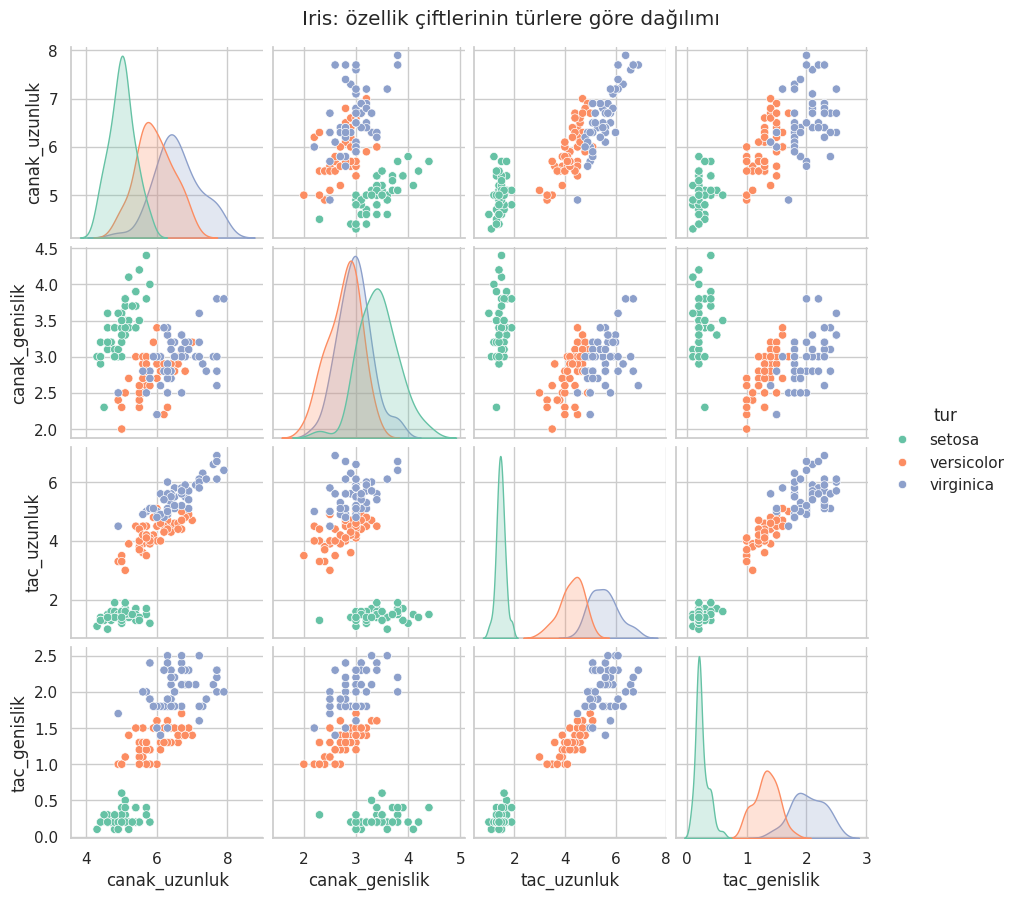

In [9]:
sns.pairplot(df, hue="tur", height=2.2, palette="Set2")
plt.suptitle("Iris: özellik çiftlerinin türlere göre dağılımı", y=1.02)
plt.show()

**Grafiğin yorumu**
- Taç uzunluğu ve taç genişliği grafiklerinde üç tür birbirinden belirgin biçimde ayrılıyor.
- *Setosa* (yeşil) diğer iki türden tamamen ayrı bir bölgede.
- *Versicolor* ve *virginica* birbirine yakın; bazı noktaları iç içe geçiyor. Modelin hata yapma ihtimalinin en yüksek olduğu yer burası.

Kutu grafiği ile taç uzunluğunun türlere göre dağılımına daha yakından bakalım. Kutunun ortasındaki çizgi medyanı, kutunun kendisi verilerin ortadaki %50'sini gösterir.

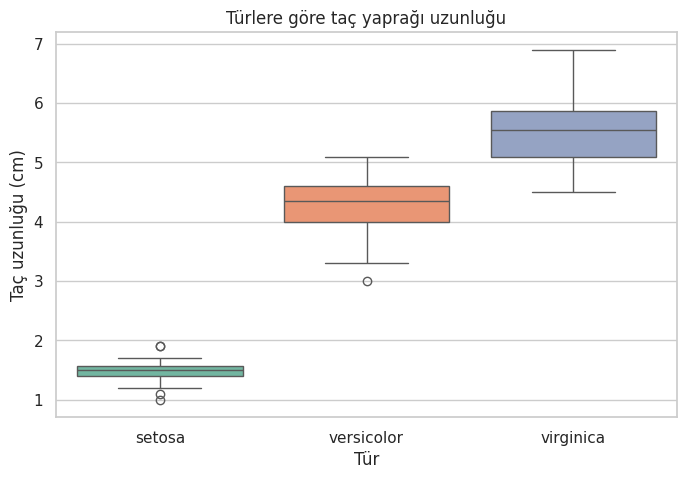

In [10]:
sns.boxplot(data=df, x="tur", y="tac_uzunluk", hue="tur", palette="Set2", legend=False)
plt.title("Türlere göre taç yaprağı uzunluğu")
plt.xlabel("Tür")
plt.ylabel("Taç uzunluğu (cm)")
plt.show()

---
## 5. Özellikleri (X) ve etiketi (y) ayırmak

scikit-learn modelleri veriyi iki parça hâlinde ister:
- **X**: modelin girdisi olan özellikler, yani dört ölçüm
- **y**: tahmin edilecek etiket, yani tür

In [11]:
ozellikler = ["canak_uzunluk", "canak_genislik", "tac_uzunluk", "tac_genislik"]

X = df[ozellikler]     # özellikler: 150 satır x 4 sütun
y = df["tur"]          # etiket: 150 değer

print("X boyutu:", X.shape)
print("y boyutu:", y.shape)

X boyutu: (150, 4)
y boyutu: (150,)


---
## 6. Eğitim ve test verisine ayırmak

Verinin %80'ini modeli eğitmek, %20'sini test etmek için kullanacağız. Test verisi eğitim sırasında modele hiç gösterilmez.

`train_test_split` fonksiyonunun parametreleri:
- `test_size=0.2`: Verinin %20'si test kümesine ayrılır.
- `random_state=42`: Bölme rastgeledir. Bu sabit sayı sayesinde kodu her çalıştırdığımızda aynı bölmeyi elde ederiz; böylece herkesin sonuçları aynı olur.
- `stratify=y`: Her türden eğitim ve test kümesine orantılı sayıda çiçek düşmesini sağlar.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Eğitim kümesi:", X_train.shape[0], "çiçek")
print("Test kümesi  :", X_test.shape[0], "çiçek")
print()
print("Test kümesindeki tür dağılımı:")
print(y_test.value_counts())

Eğitim kümesi: 120 çiçek
Test kümesi  : 30 çiçek

Test kümesindeki tür dağılımı:
tur
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


---
## 7. KNN modelini eğitmek

 **K-En Yakın Komşu (KNN) algoritması** yeni bir çiçeğin türünü belirlemek için eğitim verisinde ona en çok benzeyen **k** çiçeğe bakar ve bu komşuların çoğunluğunun türünü tahmin eder. Benzerlik, ölçümler arasındaki uzaklıkla hesaplanır.

scikit-learn'de her model iki adımda kullanılır:
1. Model nesnesi oluşturulur ve ayarları verilir: `KNeighborsClassifier(n_neighbors=5)`
2. `fit` ile eğitilir: `model.fit(X_train, y_train)`

In [13]:
model = KNeighborsClassifier(n_neighbors=5)   # k = 5 komşuya bakan bir KNN modeli
model.fit(X_train, y_train)                   # eğitim verisi (özellikler + doğru türler) ile eğit
print("Model eğitildi.")

Model eğitildi.


---
## 8. Test verisinde tahmin yapmak ve doğruluğu ölçmek

`predict` fonksiyonuna test çiçeklerinin sadece ölçümlerini (`X_test`) veriyoruz. Model her çiçek için bir tür tahmin ediyor. Sonra bu tahminleri gerçek türlerle (`y_test`) karşılaştırıyoruz.

In [14]:
y_pred = model.predict(X_test)     # test çiçeklerinin türlerini tahmin et

# İlk 10 test çiçeği için gerçek tür ve tahmini yan yana gösterelim
karsilastirma = pd.DataFrame({
    "Gerçek tür": y_test.values,
    "Tahmin": y_pred,
})
karsilastirma["Doğru mu?"] = np.where(karsilastirma["Gerçek tür"] == karsilastirma["Tahmin"], "evet", "hayır")
karsilastirma.head(10)

,Gerçek tür,Tahmin,Doğru mu?
0,setosa,setosa,evet
1,virginica,virginica,evet
2,versicolor,versicolor,evet
3,versicolor,versicolor,evet
4,setosa,setosa,evet
5,versicolor,versicolor,evet
6,setosa,setosa,evet
7,setosa,setosa,evet
8,virginica,virginica,evet
9,versicolor,versicolor,evet


In [15]:
dogruluk = accuracy_score(y_test, y_pred)
dogru_sayisi = (y_test.values == y_pred).sum()
print(f"Doğruluk: {dogruluk:.2%}")
print(f"{len(y_test)} test çiçeğinin {dogru_sayisi} tanesi doğru tahmin edildi.")

Doğruluk: 100.00%
30 test çiçeğinin 30 tanesi doğru tahmin edildi.


**Doğruluk (accuracy)**, doğru tahmin sayısının toplam tahmin sayısına oranıdır. Iris kolay bir veri seti olduğu için bu bölmede çok yüksek bir doğruluk elde ediyoruz.

---
## 9. Karmaşıklık matrisi

Karmaşıklık matrisi (confusion matrix), modelin **hangi türü hangi türle karıştırdığını** gösterir.
- **Satırlar** gerçek türü, **sütunlar** modelin tahminini gösterir.
- Sol üstten sağ alta uzanan **köşegendeki** sayılar doğru tahminlerdir.
- Köşegen dışındaki her sayı bir hatadır.

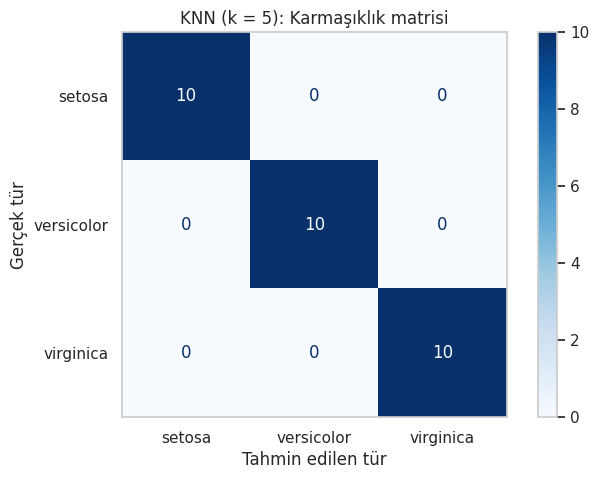

In [16]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("KNN (k = 5): Karmaşıklık matrisi")
plt.xlabel("Tahmin edilen tür")
plt.ylabel("Gerçek tür")
plt.grid(False)
plt.show()

Bu bölmede köşegende 10, 10, 10 değerleri var ve köşegen dışı tüm hücreler sıfır: KNN 30 test çiçeğinin tamamını doğru sınıflandırdı.

`classification_report` her tür için ayrıntılı ölçütleri verir:
- **precision (kesinlik):** Model "bu tür" dediklerinin ne kadarı gerçekten o tür?
- **recall (duyarlılık):** O türden gerçek çiçeklerin ne kadarı doğru bulundu?
- **f1-score:** Kesinlik ve duyarlılığın dengeli ortalaması
- **support:** Test kümesinde o türden kaç çiçek olduğu

In [17]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



---
## 10. k değerinin etkisi

`k` (komşu sayısı) modelin veriden öğrenmediği, bizim seçtiğimiz bir ayardır. Bu tür ayarlara **hiperparametre** denir. Farklı k değerleri için eğitim ve test doğruluğunu karşılaştıralım.

`model.score(X, y)` fonksiyonu tahmin yapıp doğruluğu tek adımda hesaplar.

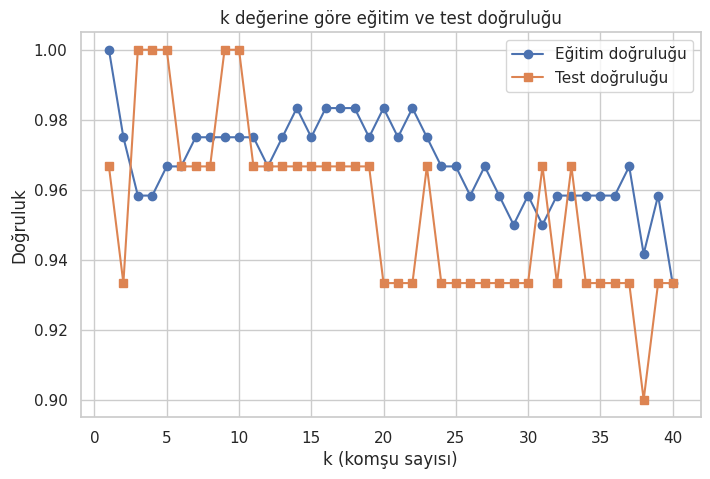

In [18]:
k_degerleri = range(1, 41)
egitim_dogruluk = []
test_dogruluk = []

for k in k_degerleri:
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_train, y_train)
    egitim_dogruluk.append(m.score(X_train, y_train))
    test_dogruluk.append(m.score(X_test, y_test))

plt.plot(k_degerleri, egitim_dogruluk, "o-", label="Eğitim doğruluğu")
plt.plot(k_degerleri, test_dogruluk, "s-", label="Test doğruluğu")
plt.xlabel("k (komşu sayısı)")
plt.ylabel("Doğruluk")
plt.title("k değerine göre eğitim ve test doğruluğu")
plt.legend()
plt.show()

**Grafiğin yorumu**
- **k = 1** iken eğitim doğruluğu %100'dür. Her eğitim çiçeğinin en yakın komşusu kendisi olduğu için model eğitim verisini ezberler. Bu, **aşırı öğrenmenin** bir örneğidir.
- **k çok büyüdüğünde** model giderek daha az ayrıntıya bakar ve doğruluk düşmeye başlar. Bu da **yetersiz öğrenmeye** doğru bir kaymadır.
- Iris küçük ve kolay bir veri seti olduğundan test doğruluğu birçok k değerinde aynı çıkabilir. 30 test çiçeğinde tek bir hata, doğruluğu %3,3 düşürür.

---
## 11. Karar ağacı

**Karar ağacı** veriden bir dizi evet/hayır sorusu öğrenir. KNN'den farklı olarak öğrendiği kurallar okunabilir. `max_depth=3` ile ağacın en fazla 3 soru derinliğinde olmasını sağlıyoruz; böylece ağaç hem okunabilir kalır hem de ezberlemeye karşı sınırlanmış olur.

Karar ağacı test doğruluğu: 96.67%


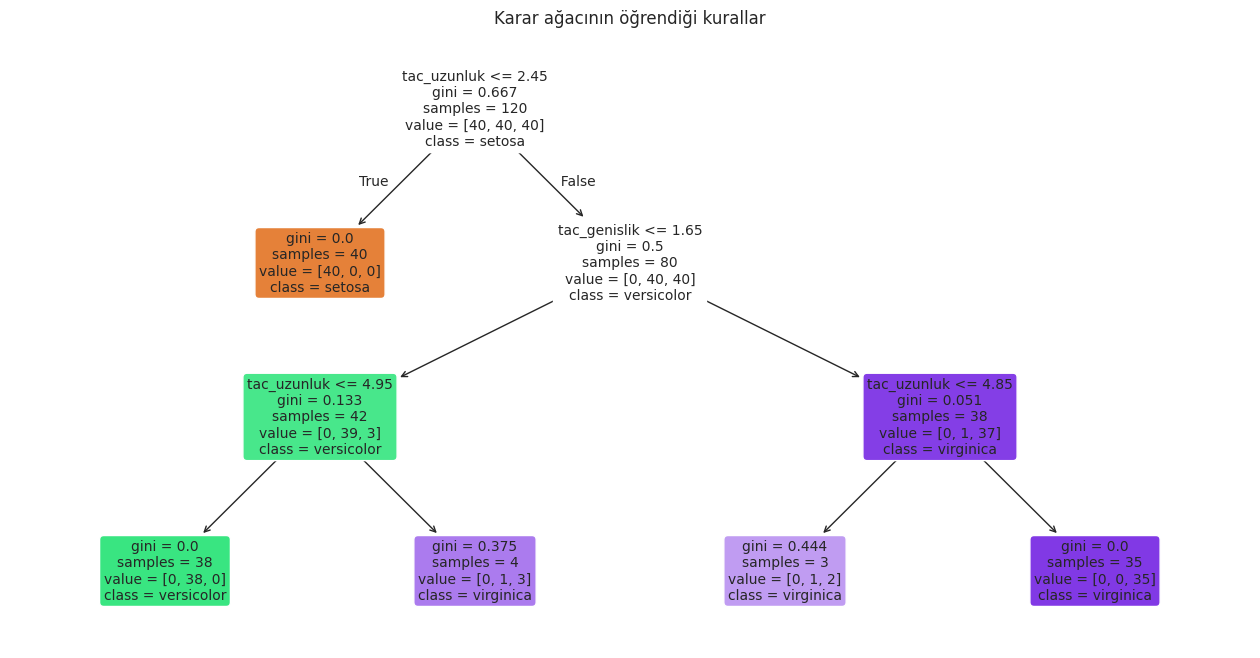

In [19]:
# Karar ağacı modelini oluştur
agac = DecisionTreeClassifier(max_depth=3, random_state=42)


# Modeli eğitim verileriyle eğit
agac.fit(X_train, y_train)

# Test doğruluğunu hesapla
print(f"Karar ağacı test doğruluğu: {agac.score(X_test, y_test):.2%}")


# Karar ağacını görselleştir
plt.figure(figsize=(16, 8))
plot_tree(agac, feature_names=ozellikler, class_names=list(agac.classes_),
          filled=True, rounded=True, fontsize=10)
plt.title("Karar ağacının öğrendiği kurallar")
plt.show()

**Ağacın okunuşu**
- Her kutunun ilk satırı sorulan sorudur (örneğin `tac_uzunluk <= 2.45`). Cevap evetse sola, hayırsa sağa gidilir.
- `samples`: O kutuya ulaşan eğitim çiçeği sayısı
- `value`: Bu çiçeklerin türlere göre dağılımı
- `class`: O kutuda çoğunlukta olan tür, yani tahmin
- Kutunun rengi koyulaştıkça içindeki çiçekler tek bir türde yoğunlaşır.

İlk soru taç uzunluğu ile ilgili: 2,45 cm'den kısaysa çiçek setosa. Görselleştirme aşamasında grafiklerde gördüğümüz ayrımı model de bulmuş oldu.

Karar ağacının test kümesindeki hatalarına karmaşıklık matrisiyle bakalım.

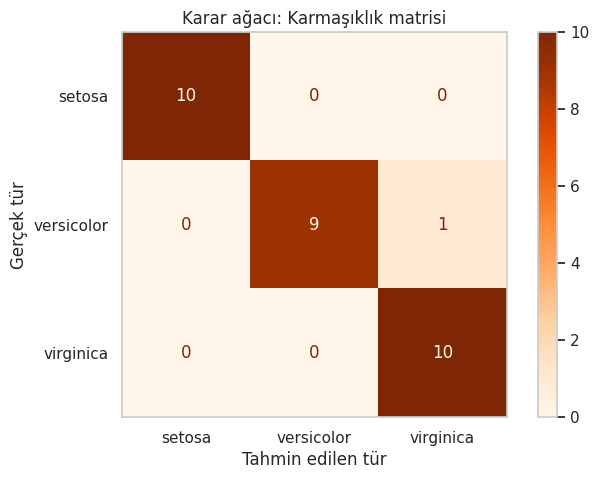

In [20]:
ConfusionMatrixDisplay.from_estimator(agac, X_test, y_test, cmap="Oranges")
plt.title("Karar ağacı: Karmaşıklık matrisi")
plt.xlabel("Tahmin edilen tür")
plt.ylabel("Gerçek tür")
plt.grid(False)
plt.show()

Karar ağacı bir çiçekte hata yaptı: Gerçekte *versicolor* olan bir çiçeği *virginica* olarak tahmin etti. Hata, pairplot grafiğinde iç içe geçtiğini gördüğümüz iki tür arasında. *Setosa* satırında hata yok.

---
## 12. Yeni bir çiçek için tahmin

Modeli eğitmemizin amacı, türünü bilmediğimiz yeni çiçekler için tahmin yapmaktır. Ölçümlerini bildiğimiz üç yeni çiçeği modele verelim.

`predict_proba` her tür için bir olasılık döndürür. KNN'de bu olasılık, 5 komşudan kaçının o türden olduğunu gösterir: 1,0 ise 5 komşunun 5'i, 0,6 ise 5 komşunun 3'ü o türdendir.

In [21]:
yeni_cicekler = pd.DataFrame(
    [[5.0, 3.4, 1.5, 0.2],     # küçük taç yaprakları
     [6.1, 2.9, 4.6, 1.4],     # orta boy taç yaprakları
     [6.3, 2.8, 5.0, 1.7]],    # versicolor ile virginica arasında bir çiçek
    columns=ozellikler,
)

tahminler = model.predict(yeni_cicekler)
olasiliklar = model.predict_proba(yeni_cicekler)

sonuc = yeni_cicekler.copy()
sonuc["tahmin"] = tahminler
for i, tur in enumerate(model.classes_):
    sonuc[f"olasılık_{tur}"] = olasiliklar[:, i].round(2)
sonuc

,canak_uzunluk,canak_genislik,tac_uzunluk,tac_genislik,tahmin,olasılık_setosa,olasılık_versicolor,olasılık_virginica
0,5.0,3.4,1.5,0.2,setosa,1.0,0.0,0.0
1,6.1,2.9,4.6,1.4,versicolor,0.0,1.0,0.0
2,6.3,2.8,5.0,1.7,virginica,0.0,0.2,0.8


Üçüncü çiçeğin ölçümleri iki türün sınırına yakın seçildi. Bu yüzden komşuları iki türe bölünüyor ve olasılıklar 1,0 değil. Gerçek uygulamalarda bu olasılık değeri, modelin ne kadar emin olduğunu gösterdiği için önemlidir.

---
## Özet

| Adım | Yaptığımız işlem | Kullandığımız araç |
|---|---|---|
| Kütüphaneler | pandas, NumPy, Matplotlib, Seaborn, scikit-learn | `import` |
| Veri okuma | CSV dosyasını tabloya dönüştürdük | `pd.read_csv` |
| Veriyi tanıma | 150 satır, 4 özellik, eksik değer yok, dengeli | `info`, `describe`, `value_counts` |
| Görselleştirme | Taç ölçüleri türleri iyi ayırıyor | `sns.pairplot`, `sns.boxplot` |
| X / y | 4 ölçüm ve tür | sütun seçimi |
| Bölme | %80 eğitim, %20 test | `train_test_split` |
| Eğitim | KNN (k = 5) ve karar ağacı | `fit` |
| Değerlendirme | Doğruluk, karmaşıklık matrisi, sınıf raporu | `accuracy_score`, `ConfusionMatrixDisplay` |
| Hiperparametre | k değerinin etkisi | döngü ve grafik |
| Kullanım | Yeni çiçek tahmini | `predict`, `predict_proba` |

### Tartışma soruları
1. `k = 1` iken eğitim doğruluğunun her zaman %100 olmasının nedeni nedir?
2. Veriyi bölmeden tüm veriyle eğitip yine tüm veriyle test etseydik hangi sorunla karşılaşırdık?
3. Modelin en çok karıştırdığı iki tür hangileri? Bunu grafiklerden önceden tahmin edebilir miydik?

### Deneyebilecekleriniz
- `test_size=0.2` değerini `0.5` yapın. Doğruluk nasıl değişti?
- `random_state=42` yerine başka bir sayı yazın. Sonuçlar neden biraz değişiyor?
- Karar ağacında `max_depth=1` deneyin. Ağaç kaç türü ayırabiliyor?
- `ozellikler` listesinden taç ölçülerini çıkarıp sadece çanak ölçüleriyle model kurun. Doğruluk ne oldu?